# Lab 7
- **Student Name**: Daniel Alejandro Castillo Martin
- **Student ID**: N10019284
- **Course:** Advanced Deep Learning - AIGC-5500-0NA
- **Professor**: Hossein Pourmodheji
---

## Lab Overview

This lab implements and verifies a variational autoencoder (VAE) on 8 × 8 digit images. It compares the VAE with a plain autoencoder, measures how the KL weight affects reconstruction and prior sampling, and evaluates latent interpolation, class conditioning, and generated samples.

## 1. Imports and Setup

In [18]:
# Import required libraries
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from pathlib import Path
from IPython.display import Image, display

# Import the starter code
from scripts import lab07_starter as S

# Import custom modules
from src.vae import VAE, vae_loss, kl_to_standard_normal, reconstruction_nll
from src.experiments import train_matched_models
from src.evaluation import evaluate_matched_models
from src.kl_sweep import evaluate_sweep_vae, train_sweep_vae
from src.interpolation import evaluate_interpolation, sample_test_pairs
import src.conditional_vae as cvae_module
from src.metric_study import score_sample_sets, measure_frechet_by_size

# Load the data
x_train, y_train, x_test, y_test = S.load_task(seed = 0)

In [2]:
# Define the dimensions of the model as constants
INPUT_DIM = 64
HIDDEN_DIM = 64
LATENT_DIM = 8

# Print the shapes of the training and test data
print(f'Training: {tuple(x_train.shape)} | Test: {tuple(x_test.shape)}')

Training: (1438, 64) | Test: (359, 64)


## 2. VAE Implementation and Verification

### 2.1 VAE Architecture

The encoder maps each 64-pixel image to the mean and log-variance of an 8-dimensional Gaussian. Reparameterization combines those values with standard normal noise so reconstruction gradients can reach the encoder. The decoder maps the sampled latent vector back to 64 pixel logits.

In [3]:
# Set the seed for reproducibility
torch.manual_seed(0)

# Initialize the VAE
vae = VAE(input_dim = INPUT_DIM, hidden_dim = HIDDEN_DIM, latent_dim = LATENT_DIM)

# Forward pass through the VAE
with torch.no_grad():
    logits, mu, logvar = vae(x_train[:4])

# Print the shapes of the decoder logits and the posterior mean and log-variance
print(f'Decoder logits: {tuple(logits.shape)}')
print(f'Posterior mean and log-variance: {tuple(mu.shape)}')

Decoder logits: (4, 64)
Posterior mean and log-variance: (4, 8)


### 2.2 VAE Loss

The VAE loss combines reconstruction error with a KL penalty. The reconstruction term sums binary cross-entropy over the 64 pixels. The KL term sums the divergence between the encoder’s Gaussian and the standard normal over the 8 latent dimensions. The weighted sum is averaged over the batch. The parameter $\beta$ controls the weight of the KL term.

In [4]:
# Calculate the initial VAE loss
with torch.no_grad():
    loss = vae_loss(vae, x_train[:4], beta = 1.0)

print(f'Initial VAE loss: {loss.item():.4f}')

Initial VAE loss: 44.3535


### 2.3 Closed-Form KL vs. Monte Carlo Estimate

For five randomly generated diagonal Gaussians, this check compares the closed-form KL divergence to a standard normal with a Monte Carlo estimate. The estimate averages $log q(z) - \log p(z)$ over samples drawn from $q$. Small differences are expected because the estimate uses a finite number of samples.

In [5]:
# Set the seed for reproducibility
generator = torch.Generator().manual_seed(0)
n_gaussians = 5
n_samples = 100_000
shape = (n_gaussians, LATENT_DIM)

# Define five diagonal Gaussians and the standard normal prior
mu_check = torch.randn(shape, generator = generator)
logvar_check = 0.5 * torch.randn(shape, generator = generator)
posterior = torch.distributions.Normal(mu_check, torch.exp(0.5 * logvar_check))
prior = torch.distributions.Normal(torch.zeros_like(mu_check), torch.ones_like(mu_check))

# Draw samples from each posterior and sum log densities over latent dimensions
noise = torch.randn((n_samples, *shape), generator = generator)
z_samples = posterior.loc + posterior.scale * noise
log_ratios = (posterior.log_prob(z_samples) - prior.log_prob(z_samples)).sum(dim = -1)

# Compare the estimate with the closed form for each Gaussian
kl_mc = log_ratios.mean(dim = 0)
kl_closed = kl_to_standard_normal(mu_check, logvar_check)
absolute_error = (kl_closed - kl_mc).abs()
mc_standard_error = log_ratios.std(dim = 0) / n_samples**0.5

for i in range(n_gaussians):
    print(f'Gaussian {i + 1} | Closed form: {kl_closed[i]:.4f} | ' f'Monte Carlo: {kl_mc[i]:.4f} | Absolute error: {absolute_error[i]:.4f}')

agreement = (absolute_error <= 4 * mc_standard_error).all().item()
print(f'All estimates within four Monte Carlo standard errors: {agreement}')

Gaussian 1 | Closed form: 4.6179 | Monte Carlo: 4.6348 | Absolute error: 0.0169
Gaussian 2 | Closed form: 2.7566 | Monte Carlo: 2.7641 | Absolute error: 0.0075
Gaussian 3 | Closed form: 7.5045 | Monte Carlo: 7.4798 | Absolute error: 0.0247
Gaussian 4 | Closed form: 2.0781 | Monte Carlo: 2.0677 | Absolute error: 0.0104
Gaussian 5 | Closed form: 4.5055 | Monte Carlo: 4.4967 | Absolute error: 0.0088
All estimates within four Monte Carlo standard errors: True


### 2.4 Reconstruction Gradient Through the Latent Sample

This check measures the gradient of the reconstruction loss with respect to the weights of the encoder’s mean head. Both cases use the same batch and latent sample. Detaching the sample preserves its values while cutting the gradient path back to the encoder.

In [6]:
# Set the seed for reproducibility
torch.manual_seed(0)
# Select a batch of images
x_batch = x_train[:32]
# Encode the images
mu, logvar = vae.encode(x_batch)
z = vae.reparameterize(mu, logvar)
mean_weights = vae.mu_head.weight

# Measure the gradient through the reparameterized sample
reconstruction = reconstruction_nll(vae.decode(z), x_batch).mean()
connected_grad, = torch.autograd.grad(reconstruction, mean_weights)
connected_norm = connected_grad.norm().item()

# Repeat with the same latent values detached from the encoder
detached_reconstruction = reconstruction_nll(vae.decode(z.detach()), x_batch).mean()
detached_grad, = torch.autograd.grad(detached_reconstruction, mean_weights, allow_unused = True)
detached_norm = 0.0 if detached_grad is None else detached_grad.norm().item()

print(f'Gradient norm with reparameterization: {connected_norm:.6f}')
print(f'Gradient norm with detached sample: {detached_norm:.6f}')
print(f'Gradient check passed: {connected_norm > 0 and detached_norm == 0}')

Gradient norm with reparameterization: 0.689904
Gradient norm with detached sample: 0.000000
Gradient check passed: True


### 2.5 Negative ELBO at β = 1

With $\beta = 1$, the VAE loss should equal the negative ELBO estimated with one latent draw per image for the reconstruction term and an exact KL term. This check computes the ELBO separately and uses the same random seed for both calculations so they use the same latent draws.

In [7]:
# Select a batch of images
x_batch = x_train[:32]

# Calculate the VAE loss at beta = 1
with torch.no_grad():
    torch.manual_seed(0)
    loss_beta_1 = vae_loss(vae, x_batch, beta = 1.0)

    # Reset the seed so both forward passes use the same latent draws
    torch.manual_seed(0)
    logits, mu, logvar = vae(x_batch)

    # Compute the reconstruction log-likelihood and KL independently
    pixel_log_prob = x_batch * F.logsigmoid(logits)
    pixel_log_prob += (1 - x_batch) * F.logsigmoid(-logits)
    log_px_given_z = pixel_log_prob.sum(dim = 1)

    posterior = torch.distributions.Normal(mu, torch.exp(0.5 * logvar))
    prior = torch.distributions.Normal(torch.zeros_like(mu), torch.ones_like(mu))
    kl = torch.distributions.kl_divergence(posterior, prior).sum(dim = 1)
    negative_elbo = -(log_px_given_z - kl).mean()

# Calculate the absolute difference between the VAE loss and the negative ELBO
difference = (loss_beta_1 - negative_elbo).abs()
agreement = torch.isclose(loss_beta_1, negative_elbo, rtol = 0, atol = 1e-5)

# Print the results
print(f'VAE loss at beta = 1: {loss_beta_1.item():.6f}')
print(f'Negative ELBO: {negative_elbo.item():.6f}')
print(f'Absolute difference: {difference.item():.2e}')
print(f'ELBO check passed: {agreement.item()}')

VAE loss at beta = 1: 44.473660
Negative ELBO: 44.473656
Absolute difference: 3.81e-06
ELBO check passed: True


## 3. Autoencoder vs. VAE

### 3.1 Matched Training

The plain autoencoder and the VAE use the same data split, hidden width, latent size, and training budget. Each model is trained for 200 epochs with Adam, a learning rate of `2e-3`, and a batch size of 64. We run both models with seeds `0`, `1`, and `2`. The autoencoder trains with mean squared error, and the VAE trains with the negative ELBO at `beta = 1`.

In [8]:
# Define the training seeds
TRAINING_SEEDS = (0, 1, 2)
# Define the number of epochs
EPOCHS = 200
LEARNING_RATE = 2e-3
BATCH_SIZE = 64

# Train the matched models
matched_models = {}
# Train the matched models for each seed
for seed in TRAINING_SEEDS:
    # Train the matched models for the current seed
    matched_models[seed] = train_matched_models(
        x_train,
        input_dim = INPUT_DIM,
        hidden_dim = HIDDEN_DIM,
        latent_dim = LATENT_DIM,
        seed = seed,
        epochs = EPOCHS,
        lr = LEARNING_RATE,
        batch_size = BATCH_SIZE
        )
    print(f'Seed {seed}: finished training the AE and the VAE')

Seed 0: finished training the AE and the VAE
Seed 1: finished training the AE and the VAE
Seed 2: finished training the AE and the VAE


### 3.2 Evaluation and Results

Both models are evaluated on test reconstruction MSE and on 359 samples decoded from the standard normal prior. The VAE uses the posterior mean for deterministic reconstruction. For each seed, both decoders receive the same prior draws. All sample scores use the same feature network and held-out reference set. Latent spread is measured as the standard deviation of each code dimension across the training images.

In [9]:
# Train the feature network 
feature_net = S.train_feature_net(x_train, y_train, seed = 0)
feature_net.eval()
# Get the test features
test_features = S.get_features(feature_net, x_test)

matched_results = {}
print('Seed | Model | Test MSE | Frechet | Precision | Recall | Nearest train')

# Evaluate the matched models for each seed
for seed, (ae, vae) in matched_models.items():
    # Evaluate the matched models for the current seed
    matched_results[seed] = evaluate_matched_models(ae, vae, x_train, x_test, feature_net, test_features, seed = seed)
    # Print the results for the current seed
    for name, result in matched_results[seed].items():
        print(f'{seed} | {name} | {result["test_mse"]:.5f} | 'f'{result["frechet"]:.3f} | {result["precision"]:.3f} | ' f'{result["recall"]:.3f} | {result["nearest_train"]:.3f}')
# Print the results for the training code standard deviations by latent dimension
print('\nTraining code standard deviations by latent dimension')
for seed, results in matched_results.items():
    for name, result in results.items():
        spread = ', '.join(f'{value:.3f}' for value in result['code_std'])
        print(f'Seed {seed} | {name}: [{spread}]')

Seed | Model | Test MSE | Frechet | Precision | Recall | Nearest train
0 | AE | 0.01524 | 72.256 | 0.384 | 0.875 | 2.055
0 | VAE | 0.02592 | 14.331 | 0.922 | 0.448 | 1.141
1 | AE | 0.01508 | 88.199 | 0.382 | 0.772 | 2.149
1 | VAE | 0.02653 | 12.685 | 0.897 | 0.412 | 1.123
2 | AE | 0.01491 | 100.596 | 0.462 | 0.749 | 2.333
2 | VAE | 0.02626 | 15.171 | 0.908 | 0.432 | 1.125

Training code standard deviations by latent dimension
Seed 0 | AE: [0.684, 0.867, 0.565, 0.629, 0.689, 0.807, 0.531, 0.669]
Seed 0 | VAE: [0.944, 0.959, 0.936, 0.481, 0.022, 0.824, 0.020, 0.034]
Seed 1 | AE: [0.630, 0.573, 0.754, 0.645, 1.086, 0.659, 0.744, 0.647]
Seed 1 | VAE: [0.904, 0.445, 0.812, 0.912, 0.894, 0.021, 0.025, 0.038]
Seed 2 | AE: [0.719, 0.763, 0.753, 0.706, 0.610, 0.707, 0.767, 0.730]
Seed 2 | VAE: [0.892, 0.919, 0.906, 0.026, 0.536, 0.820, 0.032, 0.021]


### 3.3 Prior Sample Comparison

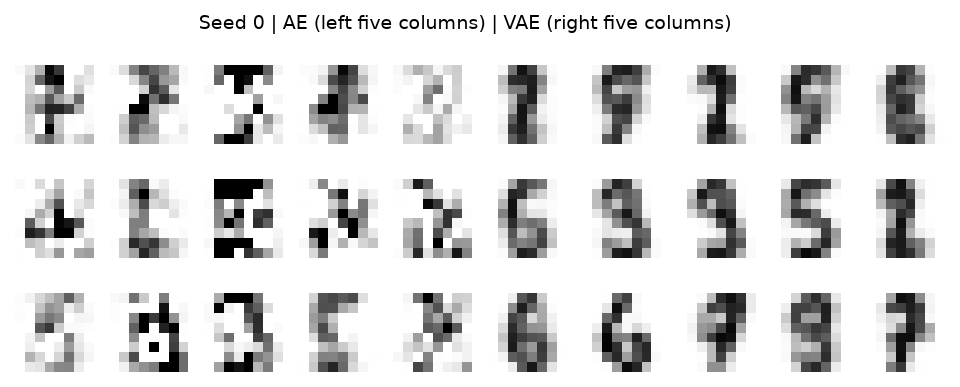

In [10]:
# Define the figure directory
figure_dir = Path('output/figures')
figure_dir.mkdir(parents = True, exist_ok = True)
figure_path = figure_dir / 'ae_vs_vae_prior_samples.png'

# Display five AE samples on the left and the corresponding VAE samples on the right
ae_samples = matched_results[0]['AE']['samples'][:15].reshape(3, 5, INPUT_DIM)
vae_samples = matched_results[0]['VAE']['samples'][:15].reshape(3, 5, INPUT_DIM)
sample_grid = torch.cat((ae_samples, vae_samples), dim = 1).reshape(-1, INPUT_DIM)

# Save the grid
S.save_grid(sample_grid, figure_path, ncols = 10, title = 'Seed 0 | AE (left five columns) | VAE (right five columns)')

# Display the image
Image(filename = str(figure_path))

The plain AE achieved lower test reconstruction MSE in all three seeds, averaging 0.01508 compared with 0.02624 for the VAE. For samples drawn from the standard normal prior, the VAE achieved a lower mean Fréchet distance (14.06 vs. 87.02) and higher mean precision (0.909 vs. 0.409). The VAE had lower mean recall (0.431 vs. 0.799), indicating that its samples covered less of the real data in feature space under this metric. In the seed 0 grid, the VAE produced more recognizable digit shapes, while several AE samples had fragmented strokes.

In each seed, three VAE posterior-mean dimensions had standard deviations below 0.04 across training images. The remaining five dimensions varied more across images. All eight AE code dimensions varied across training images. The AE's reconstruction objective placed no constraint on how its codes aligned with the standard normal prior. The VAE's KL term encouraged that alignment, consistent with its lower Fréchet distance and higher precision on prior samples.

## 4. KL-Weight Sweep

### 4.1 Training and Evaluation

This experiment varies `beta` across 0.1, 0.5, 1, 2, and 4 while keeping the architecture, data split, and training settings fixed. Each weight is evaluated across seeds 0, 1, and 2. The three models at `beta = 1` are reused from the matched comparison.

The reconstruction and KL terms are reported separately as test-set means per image. A latent dimension is active when its posterior mean has a variance above 0.01 across the training images. Each run is also evaluated on 359 prior samples using the same feature network and test reference set as in Section 3.

In [11]:
# Define the KL weights
KL_WEIGHTS = (0.1, 0.5, 1.0, 2.0, 4.0)
sweep_results = {}

# Train the sweep VAE for each beta and seed
for beta in KL_WEIGHTS:
    for seed in TRAINING_SEEDS:
        if beta == 1.0:
            model = matched_models[seed][1]
        else:
            model = train_sweep_vae(x_train, INPUT_DIM, HIDDEN_DIM, LATENT_DIM, beta, seed, epochs = EPOCHS, lr = LEARNING_RATE, batch_size = BATCH_SIZE)
        # Evaluate the sweep VAE for the current beta and seed
        result = evaluate_sweep_vae(model, x_train, x_test, feature_net, test_features, seed = seed)
        sweep_results[(beta, seed)] = result

In [12]:
# Create a DataFrame from the sweep results
sweep_df = pd.DataFrame([
    {
        'Beta': beta,
        'Seed': seed,
        'Reconstruction': result['reconstruction'],
        'KL': result['kl'],
        'Active units': result['active_units'],
        'Fréchet': result['frechet'],
        'Precision': result['precision'],
        'Recall': result['recall']
    }
    for (beta, seed), result in sweep_results.items()]).sort_values(['Beta', 'Seed'], ignore_index = True)

# Format the DataFrame for display
sweep_df.style.format({
    'Beta': '{:g}',
    'Reconstruction': '{:.4f}',
    'KL': '{:.4f}',
    'Fréchet': '{:.3f}',
    'Precision': '{:.3f}',
    'Recall': '{:.3f}'
    }).hide(axis = 'index')

Beta,Seed,Reconstruction,KL,Active units,Fréchet,Precision,Recall
0.1,0,17.2655,14.2050,8,9.748,0.733,0.866
0.1,1,17.1090,14.2085,8,10.728,0.680,0.889
0.1,2,17.1023,14.2729,8,11.812,0.713,0.869
0.5,0,19.3256,5.8331,7,8.864,0.889,0.749
0.5,1,19.3121,5.9524,7,8.653,0.830,0.643
0.5,2,19.0256,6.1410,7,9.894,0.805,0.788
1,0,21.0200,3.4785,5,14.331,0.922,0.448
1,1,21.3753,3.2206,5,12.685,0.897,0.412
1,2,20.9902,3.3034,5,15.171,0.908,0.432
2,0,24.2804,1.2615,3,45.004,0.911,0.156


### 4.2 Posterior Collapse

The grid compares prior samples from `beta = 0.5` and `beta = 4` at seed 0. Both models decode the same latent draws.

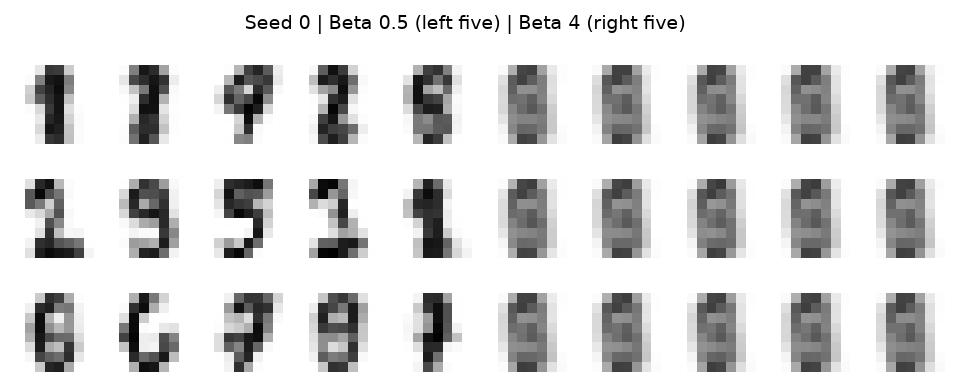

In [13]:
# Get the prior samples from beta = 0.5 and beta = 4 at seed 0
comparison_samples = sweep_results[(0.5, 0)]['samples'][:15]
collapsed_samples = sweep_results[(4.0, 0)]['samples'][:15]

# Create a grid of the samples
sample_grid = torch.cat((comparison_samples.reshape(3, 5, INPUT_DIM), collapsed_samples.reshape(3, 5, INPUT_DIM)), dim = 1).reshape(-1, INPUT_DIM)

# Define the path to save the grid
collapse_path = figure_dir / 'posterior_collapse.png'

# Save the grid
S.save_grid(sample_grid, collapse_path, ncols = 10, title = 'Seed 0 | Beta 0.5 (left five) | Beta 4 (right five)')

# Display the image
Image(filename = str(collapse_path))

Across all three seeds, increasing the KL weight reduced test KL divergence and increased reconstruction loss. The models at `beta = 0.1` had the lowest reconstruction loss and eight active units. The models at `beta = 0.5` had the lowest Fréchet distance in every seed, supporting the prediction that moderate regularization would improve prior samples.

At `beta = 4`, test KL divergence was at most 0.0012 and all three models had zero active units. These results indicate posterior collapse because the encoded distributions stayed close to the prior and their means varied too little across training images to meet the active-unit threshold. Precision reached 1.000 while recall fell to 0.000, showing that all generated samples landed within the real feature neighborhoods while none of the held-out real examples fell within the generated samples’ neighborhoods in feature space.

## 5. Probing the Latent Space

### 5.1 Latent Interpolation vs. Pixel Cross-Fade

This experiment compares three 10-step paths between 40 pairs of test images with different digit labels. The AE path interpolates between encoded vectors, the VAE path interpolates between posterior means, and the pixel baseline cross-fades directly between the original images. The same pairs are used for every method and training seed.

The feature network scores each frame. We report the mean confidence of its predicted digit across all frames and the mean number of predicted class changes between consecutive frames per path.

In [14]:
# Sample test pairs
test_pairs = sample_test_pairs(y_test, n_pairs = 40, seed = 0)

# Evaluate the interpolation
interpolation_rows = []
for seed, (ae, vae) in matched_models.items():
    results = evaluate_interpolation(ae, vae, feature_net, x_test, test_pairs, n_steps = 10)
    interpolation_rows.extend({'Seed': seed, **result} for result in results)

# Create a DataFrame from the interpolation results
interpolation_df = pd.DataFrame(interpolation_rows)
interpolation_df.style.format({
    'Mean confidence': '{:.3f}',
    'Mean class changes': '{:.2f}'}).hide(axis = 'index')

Seed,Method,Mean confidence,Mean class changes
0,AE latent,0.921,1.67
0,VAE latent,0.912,1.60
0,Pixel cross-fade,0.938,1.25
1,AE latent,0.938,1.62
1,VAE latent,0.919,1.73
1,Pixel cross-fade,0.938,1.25
2,AE latent,0.934,1.70
2,VAE latent,0.914,1.77
2,Pixel cross-fade,0.938,1.25


Pixel cross-fade had the fewest predicted class changes in every seed (1.25 per path) and a mean confidence of 0.938. AE interpolation matched that confidence to three decimal places in seed 1 and scored lower in seeds 0 and 2. VAE interpolation had lower confidence in all three seeds (0.912-0.919). Neither latent method improved on the pixel baseline across these two metrics for the sampled test pairs.

### 5.2 Class-Conditional VAE

The conditional VAE concatenates a one-hot digit label to the image before encoding and to the latent sample before decoding. It retains the 8-dimensional latent space and uses the same reconstruction and KL terms as the unconditional VAE.

In [19]:
# Define the number of classes
N_CLASSES = 10
# Convert the training labels to one-hot encoding
train_labels_one_hot = S.one_hot(y_train, n = N_CLASSES)

# Set the seed for reproducibility
torch.manual_seed(0)
conditional_vae = cvae_module.ConditionalVAE(input_dim = INPUT_DIM, hidden_dim = HIDDEN_DIM, latent_dim = LATENT_DIM, n_classes = N_CLASSES)

# Forward pass through the conditional VAE
with torch.no_grad():
    logits, mu, logvar = conditional_vae(x_train[:4], train_labels_one_hot[:4])

# Print the shapes of the one-hot labels, decoder logits, and posterior mean and log-variance
print(f'One-hot labels: {tuple(train_labels_one_hot[:4].shape)}')
print(f'Decoder logits: {tuple(logits.shape)}')
print(f'Posterior mean: {tuple(mu.shape)} | Log-variance: {tuple(logvar.shape)}')

One-hot labels: (4, 10)
Decoder logits: (4, 64)
Posterior mean: (4, 8) | Log-variance: (4, 8)


### 5.3 Conditional Generation Results

For each training seed, the conditional VAE generates 200 images per requested digit from the standard normal prior. The feature network measures the fraction of samples it assigns to the requested class. For comparison, we draw 1,000 samples from the unconditional `beta = 1` VAE for each seed and report the predicted class counts.

In [20]:
# Create a list to store the conditioning rows and a dictionary to store the conditional samples by seed
conditioning_rows = []
conditional_samples_by_seed = {}

# Train the conditional VAE for each seed
for seed in TRAINING_SEEDS:
    torch.manual_seed(seed)
    # Initialize the conditional VAE
    model = cvae_module.ConditionalVAE(input_dim = INPUT_DIM, hidden_dim = HIDDEN_DIM, latent_dim = LATENT_DIM, n_classes = N_CLASSES)
    # Train the conditional VAE
    S.train(model, cvae_module.conditional_vae_loss, x_train, y = train_labels_one_hot, epochs = EPOCHS, lr = LEARNING_RATE, batch_size = BATCH_SIZE, seed = seed)
    # Evaluate the conditional VAE for the current seed
    match_rates, class_counts, samples = cvae_module.evaluate_conditioning(model, matched_models[seed][1], feature_net, LATENT_DIM, seed, n_classes = N_CLASSES)
    conditional_samples_by_seed[seed] = samples

    for digit in range(N_CLASSES):
        conditioning_rows.append({
            'Seed': seed,
            'Digit': digit,
            'Conditional match rate': match_rates[digit].item(),
            'Unconditional count': class_counts[digit].item()
            })

# Create a DataFrame from the conditioning rows and show formatted for display
conditioning_df = pd.DataFrame(conditioning_rows)
conditioning_df.style.format({'Conditional match rate': '{:.1%}',}).hide(axis = 'index')

Seed,Digit,Conditional match rate,Unconditional count
0,0,100.0%,98
0,1,100.0%,85
0,2,100.0%,88
0,3,100.0%,124
0,4,100.0%,112
0,5,100.0%,89
0,6,100.0%,113
0,7,100.0%,92
0,8,100.0%,126
0,9,100.0%,73


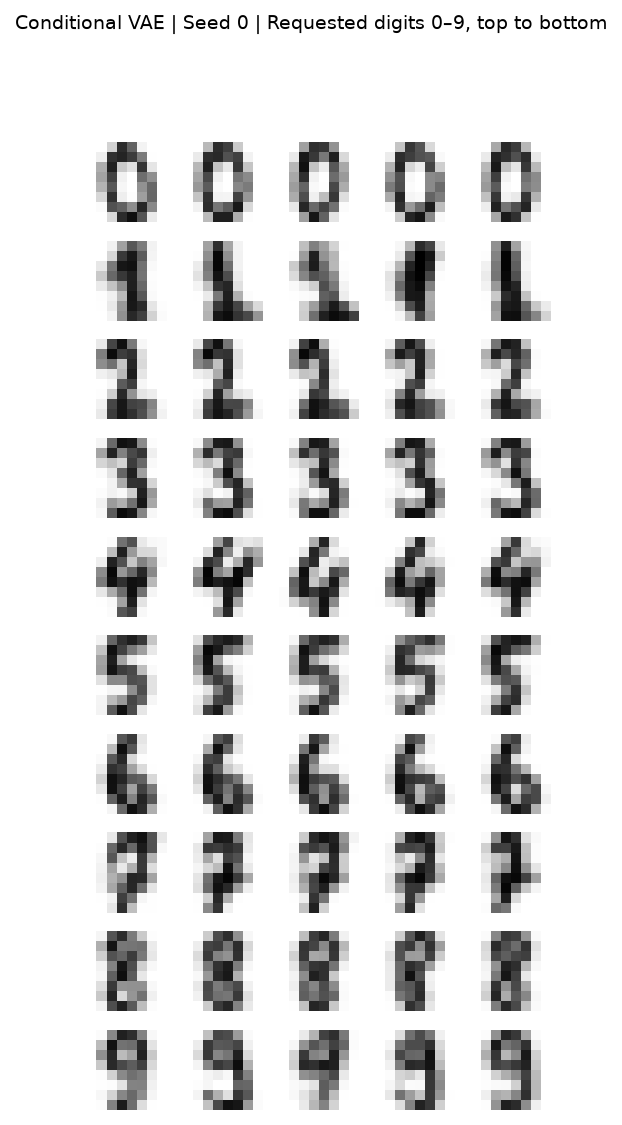

In [21]:
# Create a grid of the conditional samples
conditional_grid = conditional_samples_by_seed[0].reshape(N_CLASSES, 200, INPUT_DIM)[:, :5].reshape(-1, INPUT_DIM)
# Define the path to save the grid
conditional_path = figure_dir / 'conditional_prior_samples.png'
# Save the grid
S.save_grid(conditional_grid, conditional_path, ncols = 5, title = 'Conditional VAE | Seed 0 | Requested digits 0–9, top to bottom')
# Display the image
Image(filename = str(conditional_path))

The feature network assigned every conditional sample to its requested digit across all ten classes and all three seeds (6,000 of 6,000 samples). This measures how reliably the generated images followed the requested label according to the feature network. It does not measure how diverse the samples were within each digit class.

The unconditional VAE produced samples assigned to all ten classes in every seed, with counts ranging from 64 to 136 per class out of 1,000 draws. For example, in seed 2, the feature network assigned 136 samples to digit 3 and 78 to digit 2. Conditioning provided direct control over the requested class, while the unconditional model drew from its learned class distribution.

## 6. Generative Metrics

### 6.1 Compare Six Sample Sets

For each seed, we score six sets of 359 images against the same held-out test features. The sets are real training images, noisy copies of those images, the mean training image with noise, prior samples from the collapsed VAE (`beta = 4`), prior samples from the VAE (`beta = 1`), and prior samples from the plain AE. We report Fréchet distance, precision, recall, and mean distance to the nearest training image.

In [22]:
# Score the sample sets for each seed
metric_rows = []

for seed in TRAINING_SEEDS:
    metric_rows.extend(score_sample_sets(
        x_train,
        feature_net,
        test_features,
        matched = matched_results[seed],
        collapsed = sweep_results[(4.0, seed)],
        seed = seed
    ))

# Create a DataFrame from the metric rows
metrics_df = pd.DataFrame(metric_rows).rename(columns = {
    'frechet': 'Fréchet',
    'precision': 'Precision',
    'recall': 'Recall',
    'nearest_train': 'Nearest train'
    })

metrics_df.style.format({
    'Fréchet': '{:.3f}',
    'Precision': '{:.3f}',
    'Recall': '{:.3f}',
    'Nearest train': '{:.4f}'
    }).hide(axis = 'index')

Seed,Sample set,Fréchet,Precision,Recall,Nearest train
0,Real training images,2.833,0.900,0.911,0.0000
0,Noisy training copies,3.090,0.911,0.916,0.1340
0,Noisy mean image,140.675,0.933,0.000,1.6210
0,Collapsed VAE (beta = 4),219.270,1.000,0.000,1.5097
0,VAE (beta = 1),14.331,0.922,0.448,1.1408
0,Plain AE,72.256,0.384,0.875,2.0550
1,Real training images,2.929,0.936,0.925,0.0000
1,Noisy training copies,3.015,0.944,0.925,0.1338
1,Noisy mean image,136.992,0.967,0.000,1.6216
1,Collapsed VAE (beta = 4),218.830,1.000,0.000,1.5053


### 6.2 Fréchet Distance vs. Sample Size

We compare random subsets of the training images against the same 359 held-out test images in feature space. For each subset size, we draw ten subsets without replacement within each draw and report the mean and standard deviation of Fréchet distance. The feature network and test reference stay fixed.

In [23]:
# Measure the Fréchet distance by size
frechet_size_df = pd.DataFrame(
    measure_frechet_by_size(x_train, feature_net, test_features, sample_sizes = (30, 60, 120, 359, 1_000), n_repeats = 10, seed = 0,)
    )

# Group the Fréchet distance by subset size
frechet_size_summary = frechet_size_df.groupby('Subset size', as_index = False).agg(
    repeats = ('Fréchet', 'size'),
    mean_frechet = ('Fréchet', 'mean'),
    std_frechet = ('Fréchet', 'std')
    )

# Show the summary of the Fréchet distance by subset size
frechet_size_summary.style.format({'mean_frechet': '{:.3f}', 'std_frechet': '{:.3f}'}).hide(axis = 'index')

Subset size,repeats,mean_frechet,std_frechet
30,10,25.788,9.964
60,10,9.661,2.459
120,10,5.977,1.854
359,10,2.886,0.495
1000,10,1.838,0.247


### 6.3 Interpretation

Fréchet distance was sensitive to sample size even when both sets contained real images. Against the same 359-image test reference, the mean distance fell from 25.788 with 30 training images to 2.886 with 359 and 1.838 with 1,000. The standard deviation fell from 9.964 to 0.247 between the smallest and largest subsets. This supports using the same 359-image sample count when comparing generators.

The six-set comparison showed why the metrics are complementary. Noisy training copies scored close to real training images on Fréchet distance, but their small nearest-training distances exposed their similarity to training examples. The collapsed VAE had perfect precision and zero recall across all three seeds. Its samples fell within real feature neighborhoods, yet none of the held-out real images fell within the generated sample neighborhoods. The plain AE showed the opposite trade-off relative to the `beta = 1` VAE, with higher recall but lower precision and a larger Fréchet distance.